In [1]:
from pathlib import Path
import matplotlib.pyplot as plt

DATA_DIR = Path(r"D:\F20DL CW UG\Insurance-Fraud-Detection\Insurance-Fraud-Detection")
RESULTS = Path("../results/images")

# list of folder names used to loop over them instead of typing each one.
CLASSES = ["Fraud", "Non-Fraud"]
SPLITS = ["train", "test"]

print(DATA_DIR.exists())

True


In [2]:
# Created a function to count images in a folder.
def count_images(folder):
    n = 0 # starts the counter at zero.
    for f in folder.iterdir(): # goes through every file in the folder, one at a time.
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]: # checks if the file is an image.
            n = n + 1 # increments the counter by 1.
    return n

# Counts the number of images in each folder and print the results.
counts = {}
for split in SPLITS: # loops over each split (train, test)
    counts[split] = {}
    for c in CLASSES: # loops over each class (Fraud, Non-Fraud)
        counts[split][c] = count_images(DATA_DIR / split / c)

print(counts) 

# Calculates the percentage of fraud images in train and test sets.
train_fraud_percentage = counts["train"]["Fraud"] / (counts["train"]["Fraud"] + counts["train"]["Non-Fraud"]) * 100
test_fraud_percentage = counts["test"]["Fraud"] / (counts["test"]["Fraud"] + counts["test"]["Non-Fraud"]) * 100
print(f"Fraud is {train_fraud_percentage:.1f}% of train and {test_fraud_percentage:.1f}% of test") 

{'train': {'Fraud': 200, 'Non-Fraud': 5000}, 'test': {'Fraud': 93, 'Non-Fraud': 1323}}
Fraud is 3.8% of train and 6.6% of test


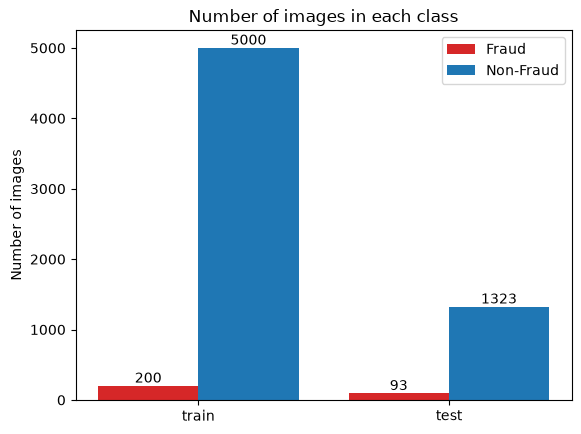

In [3]:
# Plots the number of images in each class for train and test sets (bar chart)

x = [0, 1] # sets two positions on the chart, one for train and one for test
fraud = [counts["train"]["Fraud"], counts["test"]["Fraud"]]
non_fraud = [counts["train"]["Non-Fraud"], counts["test"]["Non-Fraud"]]

bars1 = plt.bar([i - 0.2 for i in x], fraud, width=0.4, label="Fraud", color="tab:red") # plots bars for fraud images
bars2 = plt.bar([i + 0.2 for i in x], non_fraud, width=0.4, label="Non-Fraud", color="tab:blue") # plots bars for non-fraud images
plt.xticks(x, ["train", "test"]) # sets the x-axis labels
plt.ylabel("Number of images") # sets the y-axis label
plt.title("Number of images in each class") # sets the title
plt.legend() # displays the legend
plt.bar_label(bars1) # adds labels to the bars for fraud images
plt.bar_label(bars2) # adds labels to the bars for non-fraud images
plt.savefig(RESULTS / "class_counts.png", dpi=150, bbox_inches="tight") # saves the plot
plt.show() # displays the plot

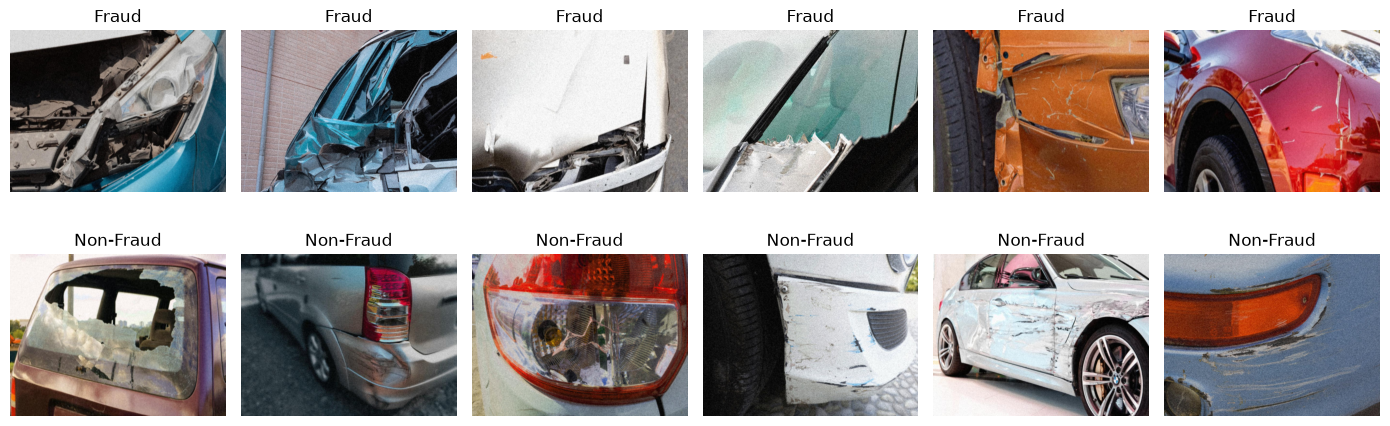

In [4]:
import random
from PIL import Image

# Function to list all image files in a folder
def list_images(folder):
    files = []
    for f in folder.iterdir():
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            files.append(f) # adds the image file to the list
    return files

random.seed(42) # sets the random seed for reproducibility

# Creates a 2x6 grid of subplots to display sample images from each class
fig, axes = plt.subplots(2, 6, figsize=(14, 5)) 
for row, c in enumerate(CLASSES): # loops over each class (Fraud, Non-Fraud)
    files = list_images(DATA_DIR / "train" / c)
    picked = random.sample(files, 6) # randomly selects 6 images from the list of image files
    for col in range(6): # loops over the 6 selected images
        img = Image.open(picked[col]) 
        axes[row, col].imshow(img)
        axes[row, col].set_title(c, fontsize=12)
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig(RESULTS / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
sizes = [] # list to store the sizes of the images
broken = [] # list to store the paths of broken images

# Loops over each split and class, and checks the size of each image. If an image is broken, it is added to the broken list.
for split in SPLITS:
    for c in CLASSES:
        for f in list_images(DATA_DIR / split / c):
            try:
                with Image.open(f) as img:
                    img.verify()
                    sizes.append(img.size)
            except Exception:
                broken.append(f)

# list of widths and heights of the images
widths = [w for (w, h) in sizes] 
heights = [h for (w, h) in sizes] 

# Prints the number of images checked, the number of broken files, the number of different sizes, 
# and the minimum and maximum width and height of the images.
print("Images checked:", len(sizes) + len(broken))
print("Broken files:", len(broken))
print("Different sizes:", len(set(sizes)))
print("Width:  min", min(widths), "max", max(widths))
print("Height: min", min(heights), "max", max(heights))

Images checked: 6616
Broken files: 0
Different sizes: 502
Width:  min 800 max 1500
Height: min 600 max 1125


In [6]:
import hashlib 

# Function to calculate the MD5 hash of a file
def file_hash(path):
    return hashlib.md5(path.read_bytes()).hexdigest()

train_hashes = {} # dictionary to store the hashes of the training images
train_count = 0
for c in CLASSES: # loops over each class
    for f in list_images(DATA_DIR / "train" / c): 
        train_hashes[file_hash(f)] = f # adds the hash of the image file to the dictionary with the file path as the value
        train_count += 1

test_hashes = {} # dictionary to store the hashes of the test images
for c in CLASSES:
    for f in list_images(DATA_DIR / "test" / c):
        test_hashes[file_hash(f)] = f 

overlap = set(train_hashes) & set(test_hashes) # finds the intersection of the two sets of hashes

# Prints the number of duplicate images inside the training set and between the training and test sets.
print("Duplicates inside train:", train_count - len(train_hashes))
print("Duplicates between train and test:", len(overlap))
for h in list(overlap)[:5]:
    print(train_hashes[h].relative_to(DATA_DIR), "<->", test_hashes[h].relative_to(DATA_DIR)) 

Duplicates inside train: 0
Duplicates between train and test: 0


In [7]:
# Calculates the average width and height of images in each class, and prints the results.
for c in CLASSES:
    w_list = []
    h_list = []
    for split in SPLITS: # loops over each split (train, test)
        for f in list_images(DATA_DIR / split / c):
            with Image.open(f) as img:
                w, h = img.size 
            w_list.append(w)
            h_list.append(h)
    avg_w = sum(w_list) / len(w_list) # calculates the average width of the images in the class
    avg_h = sum(h_list) / len(h_list) # calculates the average height of the images in the class
    print(c, "average size:", round(avg_w), "x", round(avg_h), "| width range:", min(w_list), "-", max(w_list))

Fraud average size: 1075 x 806 | width range: 800 - 1498
Non-Fraud average size: 1077 x 807 | width range: 800 - 1500
